<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 4: Human Rights approach to data y privacidad <h2><center>


# Human Rights approach to data y privacidad

>Contexto

En estos talleres, estamos trabajando con datos que pueden influir en vidas de personas. Esto implica una responsabilidad ética especial, las personas o grupos de personas detrás pueden verse impactadas tanto de forma positiva como negativa con las decisiones basadas en datos que tomemos. Antes de hacer cualquier análisis, debes preguntarte cómo tratarías esos datos si fueras quien los recolecta, y cómo podrías compartirlos si resguardar la identidad de los involucrados fuese prioridad.

>Objetivos

El objetivo de este taller es diseñar un marco de recolección de datos basado en derechos humanos sobre los problemas que han estado tratando, así como identificar si cumplen o no con el marco regulatorio chileno, aplicar DataSynthesizer para generar una versión sintética del dataset, generar visualizaciones y proponer mejoras al dataset desde la perspectiva del activismo de datos.

> # instrucciones generales

Esta es la parte IV del proyecto, consideren utilizar sus resultados anteriores y reciclar el código de los talleres previos. El taller puede aplicarse sobre cualquiera de los tres datasets del proyecto; trabajen con el mismo dataset que eligieron en los talleres anteriores y respondan cada pregunta en función de ese contexto.

Si trabajan con CIRI, notarán que sus datos son indicadores agregados por país y año, por lo que no contienen información personal que deba protegerse. Aun así, la idea es que aprendan a utilizar las herramientas de privacidad diferencial y generación de datos sintéticos, ya que el procedimiento es el mismo independiente del dataset, y que reflexionen sobre qué ocurriría si estos datos tuvieran un mayor nivel de detalle, por ejemplo, registros individuales de víctimas, como se plantea en la pregunta 6.

## `Temas formales`

Modalidad: Grupos de 3 personas.

Fecha de entrega: 20 de noviembre.

Formato de entrega: El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

Formalidades de las respuestas:
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "sí" o "no", consideren argumentar sus respuestas y justificar con bibliografía si lo estiman necesario.

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes :D.



In [49]:
# importación de librerías
import numpy as np
import pandas as pd
# import DataSynthesizer as ds
from DataSynthesizer.DataDescriber import DataDescriber
from DataSynthesizer.DataGenerator import DataGenerator
import DataSynthesizer.DataGenerator as dg
from DataSynthesizer.lib.utils import read_json_file
from DataSynthesizer.ModelInspector import ModelInspector

import matplotlib.pyplot as plt


### _`Importantes: A lo largo del notebook habrán preguntas guías para los análisis de resultados, operación de código y otros, se espera que las respondan o hagan alusión a ellas en sus respuestas `_

<br><br>
**`Pregunta (1`) Describa el objetivo y las variables del dataset desde una perspectiva distinta**.

¿A simple vista, consideras que alguna de estas variables podría ser mal utilizada, perjudicando a alguna comunidad?

¿Por qué crees que se consideran esas variables y no otras para el objetivo del dataset?

<br><br>


**Respuesta 1**: (1) Según los autores de CIRI, el objetivo del dataset es documentar las medidas de prácticas de derechos humanos y las condiciones de derechos humanos del mundo en general. (2) El dataset está diseñado para uso académico, para que los estudiantes puedan teorizar sobre las causas y consecuencias de violaciones de derechos humanos, y por ultimo para que políticos y analistas puedan estimar los efectos de los derechos humanos en varios aspectos como cambios institucionales, políticas públicas, democratizacion, ayudas económicas, etc.
(CIRI Human Rights Data Project, s.f.; McMaster University Library, s.f.)

A simple vista, podemos observar que existen varias formas de malinterpretar o usar la información del dataset de forma errónea. Pueden ser errores simples como errores de código como no eliminar los datos vacíos -999, o malinterpretar los resultados para confirmar sesgos negativos sobre ciertas poblaciones.

Se consideraron estas variables y no otras ya que el objetivo de CIRI es medir practicas gubernamentales directas y no, por ejemplo, condiciones estructurales o socioeconomicas. Además para poder cumplir con su propósito academico se necesitan variables que se puedan estandarizar y cuantificarse. Si se usaran variables mas subjetivas, sería mucho mas complicado hacer un analisis objetivo.


### `2: Exploración de datos y limpieza.`

Basta con que lo hayan realizado en los talleres anteriores, solo consideren usar el dataset limpio para lo que viene.

In [50]:
df = pd.read_csv("../S3/ciri_data.csv")
# correcion de datos
df["UN Country ID"] = df["UN Country ID"].astype("Int64")
# reemplazar codigos especiales
cod_especiales = [-999, -77, -66]
df_clean = df.copy()
columnas_derechos = df_clean.columns[6:]
for col in columnas_derechos:
    df_clean[col] = df_clean[col].replace(cod_especiales, np.nan)
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce").astype(float)

# listo :D

### `3: Análisis de principios.`

**`Pregunta (3)` Identifique si el dataset seleccionado cumple con los principios de Human Rights approach to data. Si cumple, explique por qué cumple. Si no cumple, proponga un nuevo marco de recolección o tratamiento que sí cumpla.**

Recuerda apoyarte en bibliografía externa, puedes sugerir marcos y métodos de tratamiento de datos utilizados en casos similares. Argumenta sólidamente tu elección.



**Principios a evaluar**
- Participación (Participation)
- Desagregación (Disaggregation)
- Auto-Identificación (Self-Identification)
- Transparencia (Transparency)
- Privacidad (Privacy)
- Rendición de Cuentas (Accountability)

**Participación**: "Data collectors should proactively consider participation options and groups to be represented"(OHCHR, 2018, p. 5). La base de datos de CIRI utiliza informes de "Country Reports on Human Rights Practices" de los Estados Unidos y Amnistía Internacional. Para cumplir el principio de Participación, la organización de CIRI tuvo que haber incorporado la participación de las poblaciones de cada pais evaluado. Ya que se usaron los registros historicos de otras bases de datos, concluimos que CIRI **NO** cumple con el principio de Participación.

**Desagregación**: "Disaggregation of data allows data users to compare population groups, and to understand the situations of specific groups" (OHCHR, 2018, p. 7). Aunque CIRI si separa los datos por "contextos", siendo así por año y pais, hay ciertas variables como las de "Torture" o "Free speech" que no separan cuales poblaciones sufren más de estas violaciones de derechos humanos. Tampoco hay separación de datos como por ejemplo, rural y urbano. Concluimos que CIRI cumple **PARCIALMENTE** con el principio de Desagregación.

**Auto-Identificación**: "The overriding human rights principle do no harm should always be respected" (OHCHR, 2018, p. 11) y "the parameters of the population cannot be imposed by an external party” (OHCHR, 2018, p. 12). En CIRI no son las personas quienes se identifican: los países son clasificados por codificadores externos a partir de los informes del Departamento de Estado de EE.UU. y de Amnistía Internacional y las variables de derechos de las mujeres asumen una categoría binaria de género. Además las regiones (UN Region) son asignadas desde fuera y no reflejan cómo se identifican las propias poblaciones. Como el dataset no trabaja con individuos, este principio no aplica de forma directa pero tampoco se resguarda. Concluimos que CIRI **NO** cumple con el principio de Auto-Identificación.

**Transparencia**: "Data collectors should provide clear, openly accessible information about their operations, including research design and data collection methodology. Data collected by State agencies should be openly accessible to the public" (OHCHR, 2018, p. 14). CIRI en su mismo sitio muestra de donde vienen las fuentes y mencionan que cualquier persona puede ir al documento fuente, y tienen un Codebook con las reglas de codificación públicas. Concluimos que **SI** cumplen con el principio de Transparencia.

**Privacidad**: "Access to information must be balanced with the rights to privacy and data protection" y "Data should not be published or publicly accessible in a manner that permits identification of individual data subjects, either directly or indirectly" (OHCHR, 2018, p. 16). CIRI trabaja con indicadores agregados por país y año en escalas de 0 a 2 o de 0 a 3, por lo que no contiene información que permita identificar a víctimas ni a otras personas. La privacidad se resguarda desde el diseño mismo del dataset. Sin embargo, esa misma agregación es la que limita la desagregación: proteger la privacidad y entregar detalle sobre poblaciones específicas son objetivos en tensión. Concluimos que CIRI **SI** cumple con el principio de Privacidad.

**Rendición de Cuentas**: "Accountability is central to a human rights-based approach" y "Independent statistics, free from political interference, are fundamental tools to inform and hold those in power accountable" (OHCHR, 2018, p. 18). CIRI es un proyecto académico independiente de los Estados evaluados, lo que favorece la rendición de cuentas y publica sus reglas de codificación. Sin embargo, depende en gran parte de informes de un gobierno, el de EE.UU. y Poe et al. (2001) encontraron que esos informes fueron históricamente más indulgentes con los países aliados de EE. UU. Además el proyecto dejó de actualizarse en 2011 y no tiene mecanismos para que los países o las poblaciones afectadas cuestionen o corrijan sus puntajes. Concluimos que CIRI cumple **PARCIALMENTE** con el principio de Rendición de Cuentas.

### `4: Análisis regulatorio.`

**`Pregunta (4)` Proponga un método de recolección de este tipo de datos imaginando que fuese requerido para Chile. El método debe cumplir con el marco regulatorio chileno, considerando las políticas que entraron y entrarán en vigencia.**

Proponemos que la recolección de datos sobre violaciones a derechos humanos en Chile esté a cargo del Instituto Nacional de Derechos Humanos (INDH), organismo autónomo del Estado creado por la Ley 20.405. Su independencia del gobierno responde al problema de rendición de cuentas que identificamos en CIRI. A diferencia de CIRI, el método recolectaría registros individuales (denuncias, testimonios y querellas) lo que exige cumplir con la Ley 21.719 de protección de datos personales que modifica la Ley 19.628.

1. Marco normativo vigente y futuro
    - La protección de datos personales es un derecho fundamental desde la reforma al artículo 19 N° 4 de la Constitución (Ley 21.096, 2018).
    - La Ley 21.719 entra en vigencia el 1 de diciembre de 2026. Un proyecto en trámite (boletín 18.623-07) propone postergarla al 15 de octubre de 2027, pero sin modificar sus obligaciones de fondo.
    - Por lo tanto, un método diseñado hoy debe cumplir desde ya con sus exigencias.

2. Base de licitud y datos sensibles: La información sobre violencia, detenciones o torturas, junto con datos como el origen étnico o la identidad de género corresponden a datos personales sensibles (art. 2 letra g). Por regla general solo pueden tratarse con el consentimiento expreso del titular (art. 16). Por eso cada persona que entregue su testimonio debe consentir informado, sabiendo para qué se usarán sus datos. Para los fines estadísticos y de investigación del registro, el art. 16 quinquies permite el tratamiento con resguardos especiales. Si la víctima es menor de edad se aplica el art. 16 quáter, que prioriza el interés superior del niño, niña o adolescente.

3. Principios del art. 3 aplicados al diseño
    - Finalidad: los datos se usan solo para monitorear derechos humanos, nunca para fines policiales o de inteligencia sin una orden judicial.
    - Proporcionalidad: se recolecta solo lo necesario para ese fin.
    - Seguridad y confidencialidad: se usa acceso restringido y los datos identificatorios se separan del resto mediante seudonimización (art. 2 letra l) desde el momento de la recolección.

4. Evaluación de impacto: Como hablamos de un tratamiento a gran escala de datos sensibles, antes de comenzar se realizaría una evaluación de impacto en protección de datos (art. 15 ter) para identificar riesgos como la reidentificación de víctimas o represalias contra denunciantes.

5. Integración de los principios del Human Rights approach to data, corrigiendo las falencias de CIRI:
    - **Participación**: el diseño del formulario y de las categorías se haría junto a organizaciones de víctimas, de pueblos indígenas y de la diversidad sexual.

    - **Desagregación y auto-identificación**: se registraría la región, la zona (rural/urbana), la edad y el género, este último con respuesta libre y respetando la identidad de género reconocida por la Ley 21.120. La pertenencia a pueblos indígenas o afrodescendientes sería siempre auto-declarada.

    - **Transparencia**: el libro de códigos y la metodología serían públicos, en línea con la Ley 20.285 de acceso a la información pública.

    - **Privacidad**: los datos individuales nunca se publican. Solo se publican estadísticas agregadas, con datos anonimizados de forma irreversible (art. 2 letra k) o versiones sintéticas generadas con privacidad diferencial.

    - **Rendición de cuentas**: la Agencia de Protección de Datos Personales (art. 30) fiscalizaría el cumplimiento, y las personas podrían ejercer sus derechos de acceso, rectificación, supresión, oposición y portabilidad sobre sus datos

En síntesis, el método propuesto busca un equilibrio: entregar datos lo bastante detallados para la búsqueda de justicia y el activismo, sin exponer a las personas que los entregan.

<br><br>
### `5: Privacidad diferencial.`

**`Pregunta (5)` Aplica las técnicas de privacidad diferencial vistas para anonimizar el dataset y comenta los resultados.**

#### **Parte 1:**

- (a) Selecciona a lo más 7 variables para aplicar la técnica. Menciónalas y justifica tu elección.
- (b) Obtenga la descripción del dataset en alguno de los modos, justifique su elección. Guarde dicha descripción en un archivo local (en formato JSON)
- (c) Genere los datos sintéticos usando DataGenerator
- (d) Aplique ModelInspector para comparar las distribuciones entre los datos originales y los datos sintéticos.

<br><br>

#### a) Selección de variables

In [51]:
# código aquí.
df_clean.columns

Index(['Year', 'CIRI Country ID', 'Country', 'UN Country ID', 'UN Region',
       'UN Subregion', 'Physical Integrity Rights Index', 'Disappearance',
       'Extrajudicial Killing', 'Political Imprisonment', 'Torture',
       'Empowerment Rights Index (Old)', 'Empowerment Rights Index (New)',
       'Freedom of Assembly and Association', 'Freedom of Foreign Movement',
       'Freedom of Domestic Movement', 'Freedom of Movement (Old)',
       'Freedom of Speech', 'Electoral Self-Determination',
       'Freedom of Religion (Old)', 'Freedom of Religion (New)',
       'Employment Rights', 'Women’s Economic Rights',
       'Women’s Political Rights', 'Women’s Social Rights',
       'Independence of Judiciary'],
      dtype='object')

Variables a privatizar:

1. `Extrajudicial Killing`
2. `Political Imprisonment`
3. `Freedom of Assembly and Association`
4. `Freedom of Speech`
5. `Electoral Self-Determination`
6. `Freedom of Religion (New)`
7. `Women’s Social Rights`

Estas variables pueden presentar por experiencia empírica relación entre sí, como `Extrajudicial Killing` - `Political Imprisonment`, `Freedom of Assembly and Association` - `Freedom of Speech` - `Political Imprisonment`, `Freedom of Speech` - `Electoral Self-Determination`, `Freedom of Speech` - `Freedom of Religion (New)`, o `Freedom of Speech` - `Women’s Social Rights`. Éstas relaciones no son verificadas pero más adelante en el heatmap de los datos originales se observa que algunas de estas relaciones se cumplen.


In [52]:
cols = ['Extrajudicial Killing', 'Political Imprisonment',
        'Freedom of Assembly and Association', 'Freedom of Speech',
        'Electoral Self-Determination', 'Freedom of Religion (New)', 'Women’s Social Rights']

df_analyze = df_clean[cols].copy()
df_analyze.info()

# se guarda en un csv pues datasyntetizer no procesa dataframes de pandas
df_analyze.to_csv('CIRI-rights-analyze.csv', index=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6262 entries, 0 to 6261
Data columns (total 7 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Extrajudicial Killing                4931 non-null   float64
 1   Political Imprisonment               4939 non-null   float64
 2   Freedom of Assembly and Association  4942 non-null   float64
 3   Freedom of Speech                    4947 non-null   float64
 4   Electoral Self-Determination         4947 non-null   float64
 5   Freedom of Religion (New)            5542 non-null   float64
 6   Women’s Social Rights                3653 non-null   float64
dtypes: float64(7)
memory usage: 342.6 KB


In [53]:
source = 'CIRI-rights-analyze.csv' # path al csv limpio del dataframe limpio

# Se instancia DataDescriber y DataGenerator.
describer = DataDescriber()
generator = DataGenerator()
n_cols_20 = int(len(df_analyze) * 0.25)# 25% de los datos originales, más pequeño para no saturar la memoria
print(f"Se generarán {n_cols_20} datos sintéticos, que es el 25% de los datos originales.")

Se generarán 1565 datos sintéticos, que es el 25% de los datos originales.


#### b) Descripción (Data Describer):

2. Correlated Attribute Mode

In [54]:
# Se genera la descripción del dataset.
describer.describe_dataset_in_correlated_attribute_mode(source, k=2)

# Se genera la descripción en un archivo local.
describer.save_dataset_description_to_file("correlated.json")

================ Constructing Bayesian Network (BN) ================
Adding ROOT Women’s Social Rights
Adding attribute Freedom of Speech
Adding attribute Electoral Self-Determination
Adding attribute Freedom of Assembly and Association
Adding attribute Political Imprisonment
Adding attribute Extrajudicial Killing
Adding attribute Freedom of Religion (New)
========================== BN constructed ==========================


#### c) Datos sintéticos (Data Generator):

2. Correlated Attribute Mode

In [55]:
dg.np = np # type: ignore

# Se generan los datos sintéticos.
generator.generate_dataset_in_correlated_attribute_mode(
    n=n_cols_20, description_file="correlated.json", seed=10
)

# Se guardan los datos sintéticos.
generator.save_synthetic_data("correlated.csv")
# Se verifica que efectivamente se hayan creado datos sintéticos.
correlated = pd.read_csv("correlated.csv")
correlated.head()

,Extrajudicial Killing,Political Imprisonment,Freedom of Assembly and Association,Freedom of Speech,Electoral Self-Determination,Freedom of Religion (New),Women’s Social Rights
0,2.0,NaN,1.0,0.0,2.0,2.0,NaN
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.0,0.0,2.0,NaN,2.0,2.0,3.0
3,2.0,NaN,2.0,NaN,NaN,0.0,NaN
4,0.0,2.0,2.0,2.0,2.0,2.0,2.0


In [56]:
correlated.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 7 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Extrajudicial Killing                1317 non-null   float64
 1   Political Imprisonment               1179 non-null   float64
 2   Freedom of Assembly and Association  1209 non-null   float64
 3   Freedom of Speech                    1109 non-null   float64
 4   Electoral Self-Determination         1279 non-null   float64
 5   Freedom of Religion (New)            1354 non-null   float64
 6   Women’s Social Rights                1054 non-null   float64
dtypes: float64(7)
memory usage: 85.7 KB


#### d) Comparación de distribuciones (Model Inspector):

Aquí se comparan las distribuciones de los datos originales y los distintos datos sintéticos.

2. Correlated Attribute Mode

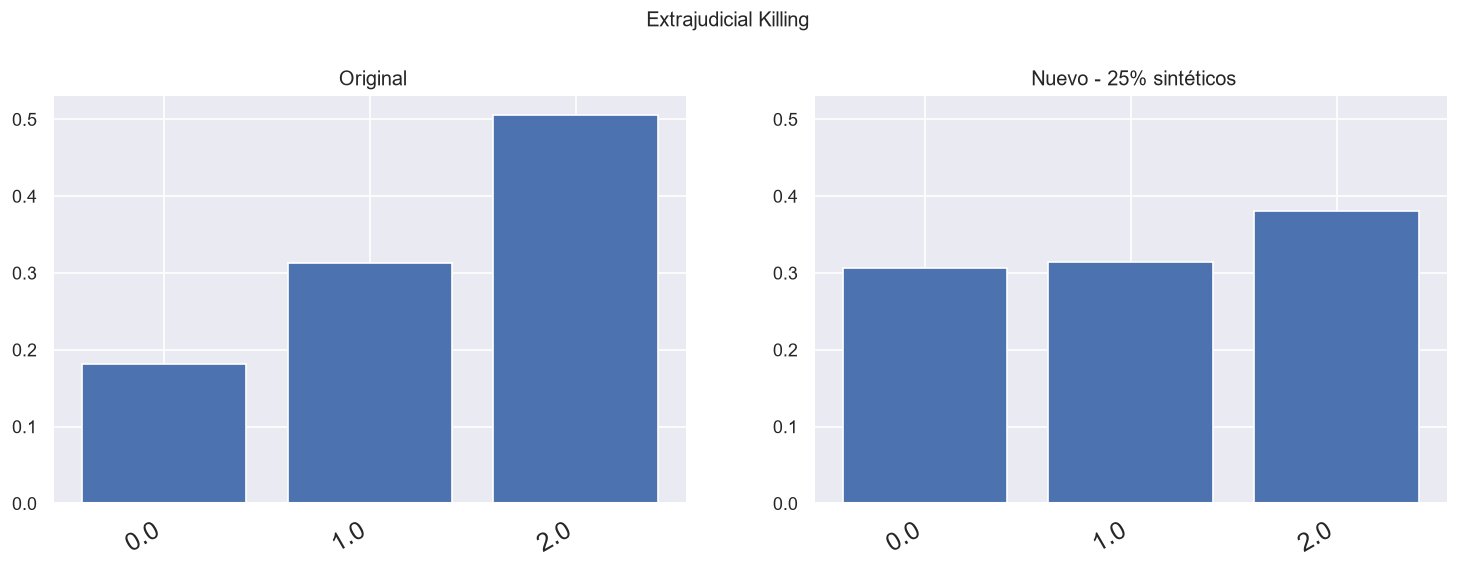

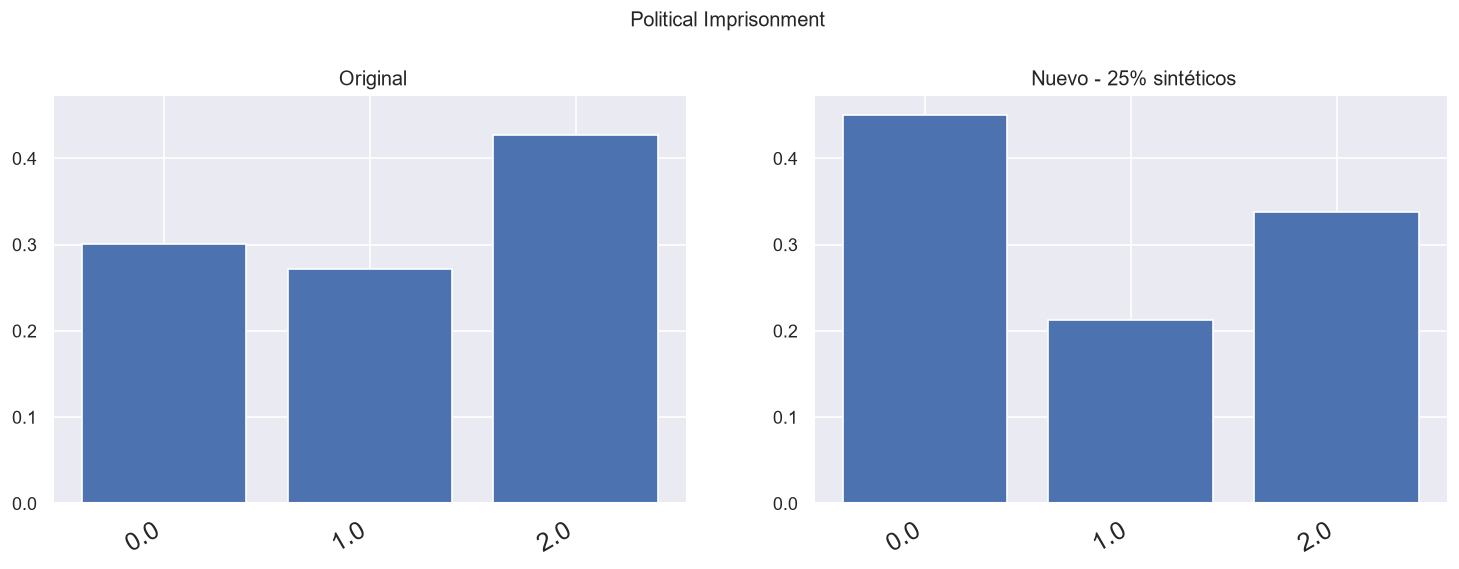

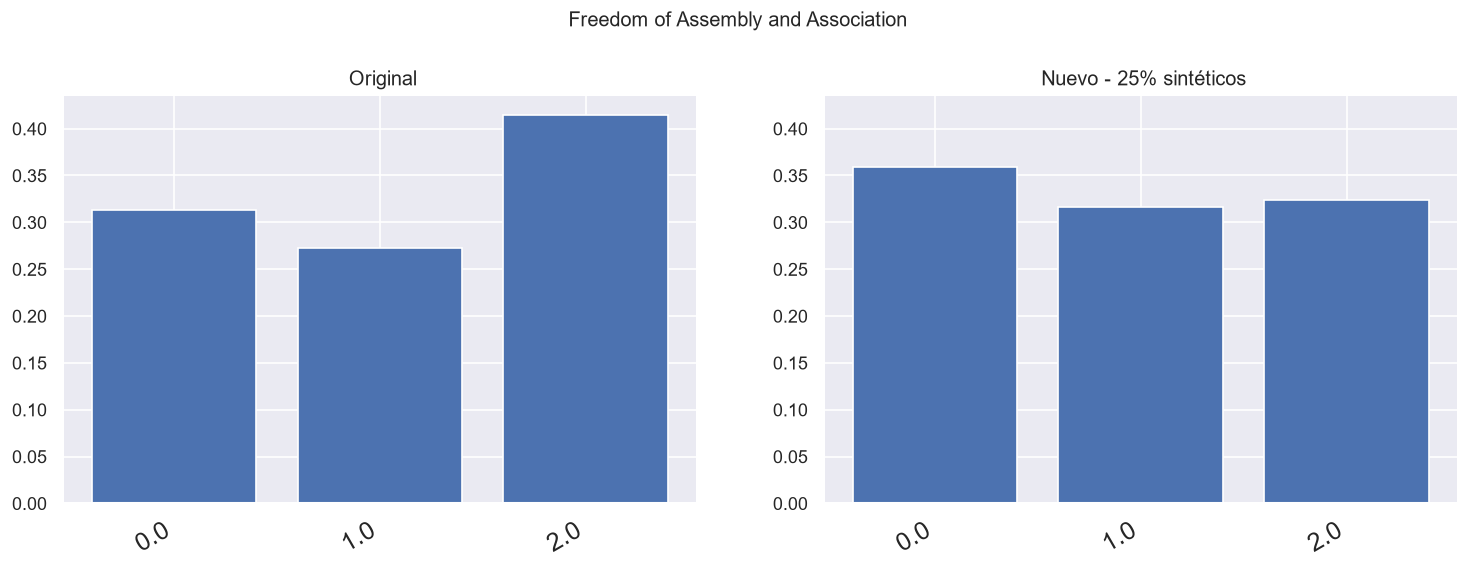

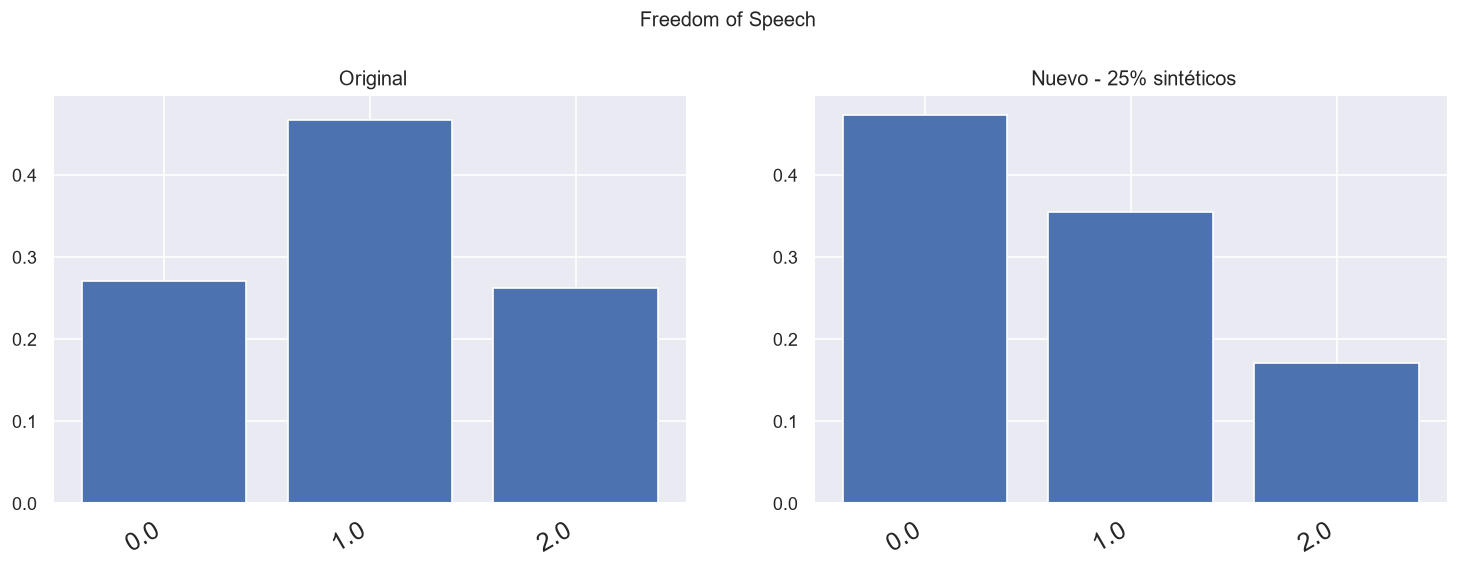

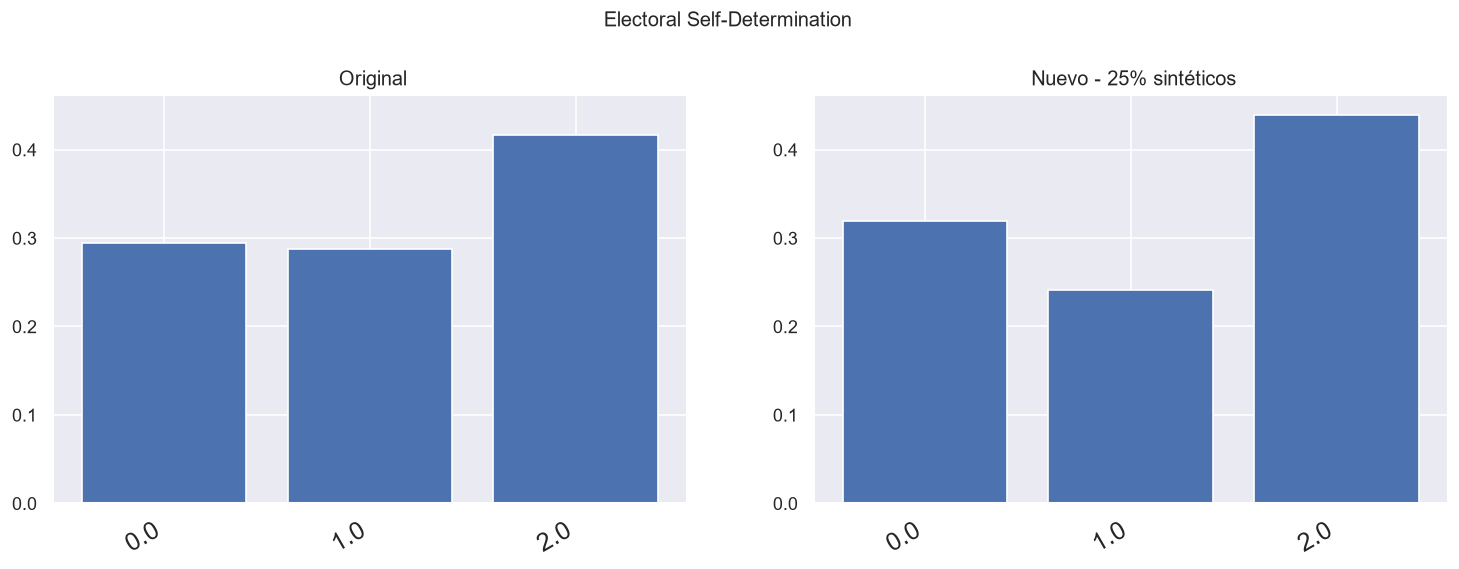

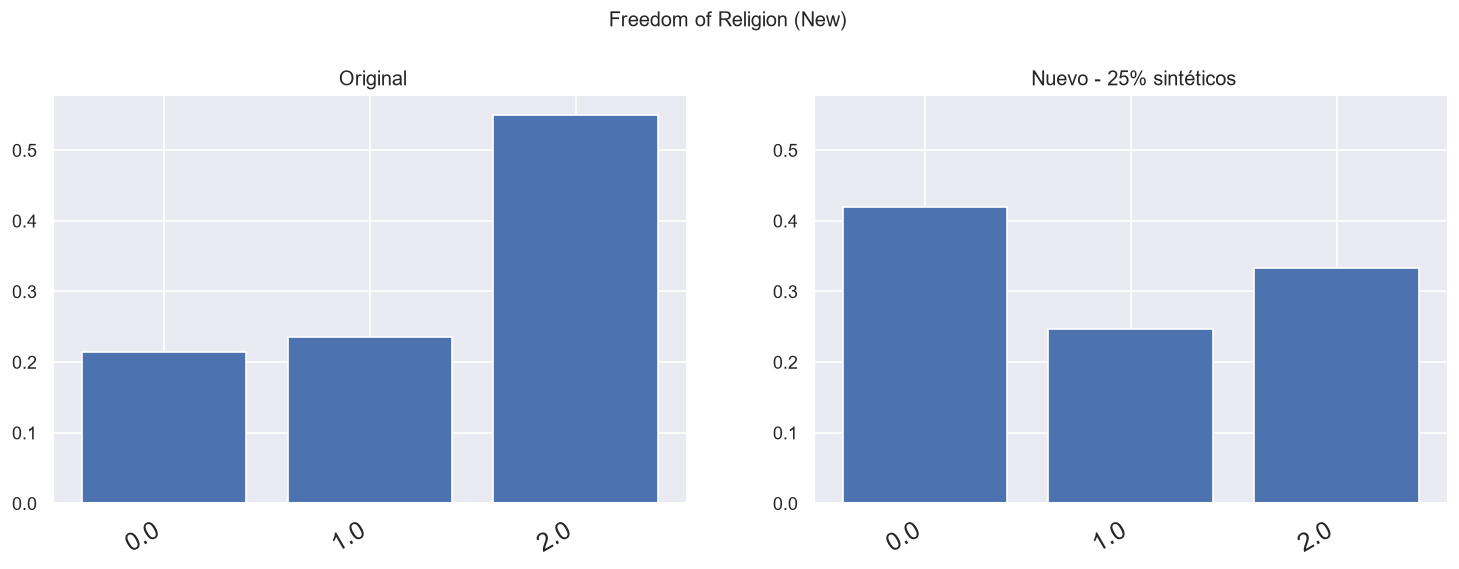

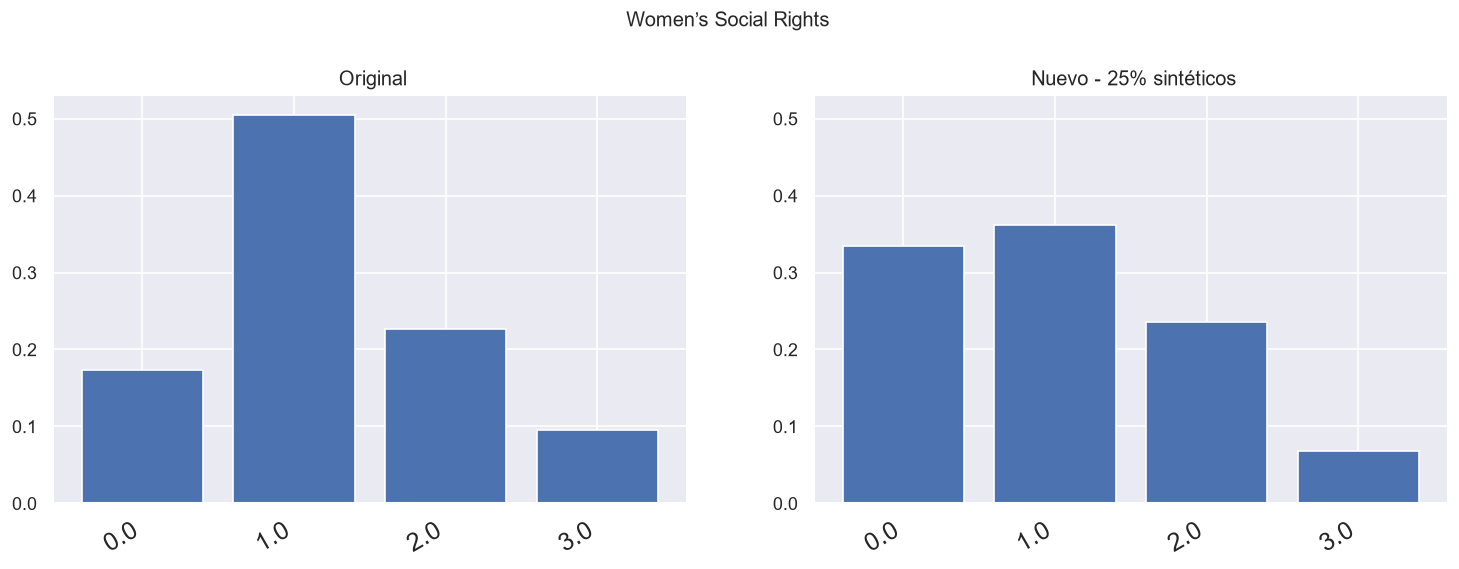

In [57]:
# Instanciamos ModelInspector
correlated_description = read_json_file("correlated.json")["attribute_description"]
c_inspector = ModelInspector(df_analyze, correlated, correlated_description)

# Con ModelInspector podemos comparar las distribuciones de los atributos.
for attr in correlated.columns:
    c_inspector.compare_histograms(attr)
    
    fig = plt.gcf()
    fig.suptitle(
        f"{attr}",
        fontsize=12,
        y=1.02
    )
    
    # Etiqueta de cada eje de cada subgráfico
    if len(fig.axes) >= 2:
        fig.axes[0].set_title(f"{fig.axes[0].get_title()} Original")
        fig.axes[1].set_title(f"{fig.axes[1].get_title()} Nuevo - 25% sintéticos")
    
    plt.show()

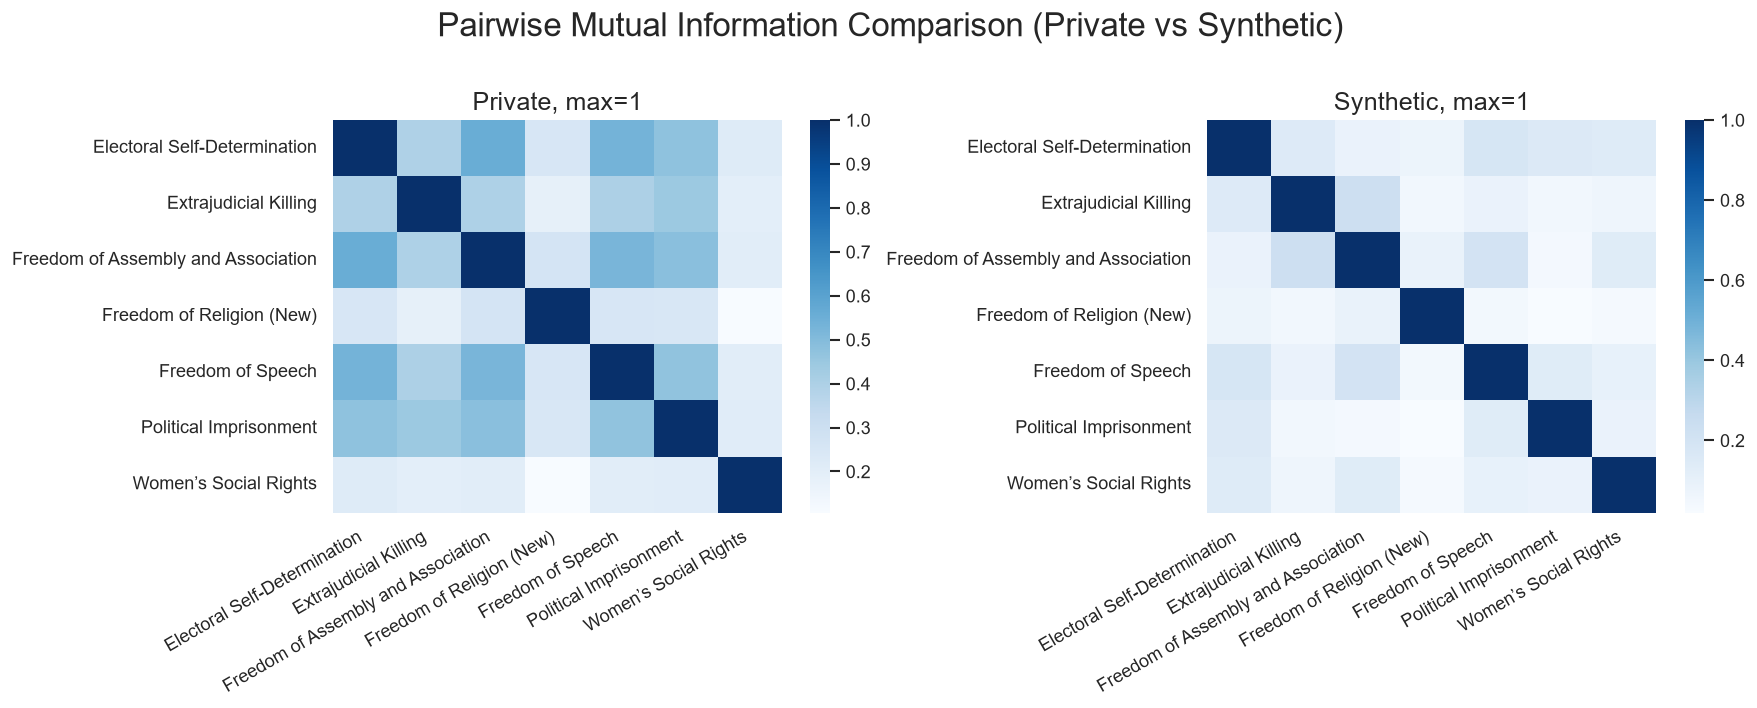

In [58]:
c_inspector.mutual_information_heatmap()

A partir de los histogramas se ve que el sistema del modo Correlacional pierde características del dataset original, entre ellas las proporciones y distribuciones del dominio de cada variable y la correlación entre variables como `Freedom of Assambly and Association` y `Electoral Self-Determination`, o `Freedom of Speech` y `Electoral Self-Determination`, o `Freedom of Speech` y `Freedom of Assambly and Association`, o `Extrajudicial Killing` y `Political Imprisonment`.

#### **Parte 2:**

Imagina que ahora cuentas con este mismo dataset con información mucho más detallada, que podría contribuir a un proyecto desde la Ciencia de Datos con impacto social. Dependiendo del dataset que haya escogido su grupo, consideren el siguiente escenario:

- CIRI: el dataset incluye locaciones específicas, familias y detalles de investigación sobre desapariciones y asesinatos, lo que podría contribuir a un proyecto de búsqueda de víctimas.

En este caso podríamos preguntarnos, ¿qué sería lo correcto? ¿anonimizar o mantener pública toda la información?

<br>


Con un dataset de CIRI enriquecido con locaciones específicas, datos familiares y detalles de investigación sobre desapariciones y asesinatos, lo éticamente correcto es seudonimizar los identificadores directos y sensibles (como domicilios exactos, nombres de familiares, información de contacto o números de identificación nacional) y someter el acceso a protocolos estrictos de gobernanza, evitando su publicación indiscriminada de los datos. Si bien el propósito de contribuir a la búsqueda de víctimas posee un alto valor social, mantener la totalidad de los registros públicos vulneraría la privacidad como bien colectivo y expondría a las familias a riesgos de seguridad, extorsión, estigmatización y revictimización secundaria.

Desde una perspectiva ética, la privacidad funciona como un escudo indispensable frente a las asimetrías de poder. Como sostiene *Véliz (2020)*, la privacidad no es una preferencia individual, sino una condición colectiva necesaria para proteger la autonomía y la integridad de las personas frente a terceros que podrían hacer uso de su información. En contextos de violaciones a los derechos humanos como este, divulgar sin resguardo los datos de contacto o localización de los familiares elimina su capacidad de decidir quién, cuándo y bajo qué condiciones puede acercarse a ellos, transfiriéndoles de manera injusta el costo y el riesgo de la exposición pública.

Asimismo, la transparencia no equivale a la apertura total e irrestricta de registros sensibles. La privacidad constituye uno de los principales límites normativos y moderadores de la transparencia: abrir datos sin filtros cuando existen riesgos para sujetos vulnerables resulta éticamente erróneo. Por ello, resulta necesario separar la utilidad analítica y humanitaria (como patrones geoespaciales agregados o registros seudonimizados que permitan cruzar pistas de búsqueda) de la identidad directa de las familias, reservando la reidentificación únicamente para organismos especializados, autoridades competentes o equipos acreditados bajo acuerdos de confidencialidad y consentimiento informado.

Desde el enfoque de la responsabilidad profesional, quienes diseñan y gestionan proyectos de impacto social tienen el deber de ejercer el cuidado (care) y la prudencia (Socratism) frente a los efectos previsibles de sus herramientas sobre comunidades vulnerables *(Howard, 2020; Vallor, 2016)*. Seudonimizar la información crítica y articular una gobernanza responsable permite habilitar el análisis de datos para la localización de víctimas sin vulnerar la dignidad, el consentimiento ni la seguridad de sus familias.

<br><br>

### `6: Activismo de datos.`

**`Pregunta (6)` Proceso de toma de decisiones: Frente a este dilema concreto ¿incluir todos los datos por precisión y transparencia o aplicar técnicas de privacidad para proteger a las personas y sus familias? ¿cómo lo resolverías? cuales son los pros y los contras de esta decisión, en que tipo de contextos compartirías los datos reales y en cuales los datos sinteticos.**

**(IDEA BASE según lo que lei en la guia de la ONU)**
<br> 
A Human Rights-Based Approach to Data (OHCHR, 2018)

"In some cases, such as human rights monitoring, it is necessary and useful to publish data that identifies individuals. This may occur when an individual has been the victim of a crime/human rights violation and the publication of information about the incident is necessary to hold the perpetrators to account. This should only be done where strictly necessary, and only where permission has been given by the individual concerned. In the case of persons who are deceased or who have been kidnapped, detained or disappeared, permission could come from their family or close associates." (OHCHR, 2018, p. 17)

Dice que en el monitoreo de derechos humanos a veces es necesario publicar datos que identifiquen a una víctima para hacer responsables a los perpetradores, pero solo con permiso de la persona o si está desaparecida o fallecida.
<br>
**(FIN IDEA BASE)**

Hay que completarla



In [59]:
# código aquí.

**`Pregunta (7)` Reporte los resultados de la técnica de anonimización (ModelInspector) y explique como se podría realizar activismo de datos con el conjunto anonimizado.**



In [60]:
# código aquí.

# **Referencias**
- CIRI Human Rights Data Project. (s.f.). *FAQ*. http://www.humanrightsdata.com/p/faq.html

- Ley 19.628. (1999). *Sobre protección de la vida privada*. Ministerio Secretaría General de la Presidencia. Modificada por la Ley 21.719 (2024).

- Ley 20.405. (2009). *Del Instituto Nacional de Derechos Humanos*. Ministerio Secretaría General de la Presidencia.

- Ley 20.285. (2008). *Sobre acceso a la información pública*. Ministerio Secretaría General de la Presidencia.

- Ley 21.096. (2018). *Consagra el derecho a protección de los datos personales*. Ministerio Secretaría General de la Presidencia

- Ley 21.120. (2018). *Reconoce y da protección al derecho a la identidad de género*. Ministerio de Justicia y Derechos Humanos.

- Ley 21.719. (2024, 13 de diciembre). *Regula la protección y el tratamiento de los datos personales y crea la Agencia de Protección de Datos Personales*. Diario Oficial de la República de Chile. https://www.diariooficial.interior.gob.cl/publicaciones/2024/12/13/44023/01/2583630.pdf

- McMaster University Library. (s.f.). CIRI Human Rights Data Project. https://library.mcmaster.ca/data/ciri-human-rights-data-project

- Office of the United Nations High Commissioner for Human Rights. (2018). *A human rights-based approach to data: Leaving no one behind in the 2030 Agenda for Sustainable Development*. https://www.ohchr.org/sites/default/files/Documents/Issues/HRIndicators/GuidanceNoteonApproachtoData.pdf

- Poe, S. C., Carey, S. C., & Vazquez, T. C. (2001). How are these pictures different? A quantitative comparison of the US State Department and Amnesty International human rights reports, 1976–1995. *Human Rights Quarterly*, 23(3), 650–677.

- Véliz, C. (2020). Privacidad es poder: Datos, vigilancia y libertad en la era digital (Cap. 3).

- Diakopoulos, N. (2020). Transparency. En M. D. Dubber, F. Pasquale, & S. Das (Eds.), The Oxford handbook of ethics of AI (pp. 197–213).

- Howard, D. (2020). Technomoral civic virtues. En C. Véliz (Ed.), The Oxford handbook of digital ethics.

- Vallor, S. (2016). Technology and the virtues: A philosophical guide to a future worth wanting. https://api.pageplace.de/preview/DT0400.9780190498528_A30388626/preview-9780190498528_A30388626.pdf